# Exploratory Analysis: Predicting Fear During VR Spider Exposure

This notebook explores the dataset used throughout this project: Krumnikl et al. (2026),
*"Do Virtual Spiders Feel Real? Dissociation Between Subjective and Physiological Fear
During Virtual Reality Exposure"* (Zenodo, DOI [10.5281/zenodo.20796399](https://doi.org/10.5281/zenodo.20796399), CC-BY-4.0).

It covers:
1. Dataset shape, participants, and validation
2. Target (SUDS) distribution and exposure stages
3. Physiological features across exposure levels
4. Within- vs. between-participant variation
5. Subjective-physiological agreement and dissociation
6. A from-scratch raw-signal processing demo (NeuroKit2) with a sanity check against the
   precomputed features
7. Model comparison results (context-only vs. physiology-only vs. combined)
8. Robustness: is the context-vs-combined result stable across repeated participant
   holdouts, and does excluding the baseline (floor-effect) level change it?

Run `python -m vr_fear_prediction.download_data`, `python -m vr_fear_prediction.data`, and
`python -m vr_fear_prediction.modeling` before running this notebook, so
`data/raw/summary.csv`, `data/processed/features_long.csv`, and `reports/metrics.json`
exist.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from vr_fear_prediction.data import build_long_dataset, load_raw_summary, validate_raw_summary
from vr_fear_prediction import evaluation, visualization

sns.set_theme(style="whitegrid", context="notebook")
PROJECT_ROOT = Path.cwd().parent
pd.set_option("display.max_columns", 50)


## 1. Dataset shape, participants, and validation

In [2]:
raw_df = load_raw_summary(PROJECT_ROOT / "data" / "raw" / "summary.csv")
print("Raw summary.csv shape:", raw_df.shape)
report = validate_raw_summary(raw_df)
print(f"Participants: {report.n_participants}")
print(f"Valid: {report.is_valid}")
print(f"Duplicate participants: {report.duplicate_participants}")
print(f"Out-of-range SUDS ratings: {report.out_of_range_suds}")


Raw summary.csv shape: (28, 179)
Participants: 28
Valid: True
Duplicate participants: []
Out-of-range SUDS ratings: []


In [3]:
long_df, report = build_long_dataset(PROJECT_ROOT / "data" / "raw" / "summary.csv")
print("Long-format dataset shape:", long_df.shape)
print(f"{report.n_participants} participants x 10 exposure levels (0=baseline, 1-9=escalating spider tasks)")
long_df.head()


Long-format dataset shape: (280, 42)
28 participants x 10 exposure levels (0=baseline, 1-9=escalating spider tasks)


,participant_id,level,suds,PPG_HR,PPG_HR_delta_baseline,PULSE_HR,PULSE_HR_delta_baseline,RESP_RATE,RESP_RATE_delta_baseline,EDA_MEAN,EDA_MEAN_delta_baseline,HRV_SDNN,HRV_SDNN_delta_baseline,HRV_RMSSD,HRV_RMSSD_delta_baseline,HRV_LFHF,HRV_LFHF_delta_baseline,WATCH_STD,WATCH_STD_delta_baseline,WATCH_RMSSD,WATCH_RMSSD_delta_baseline,WATCH_REACTIVITY,WATCH_REACTIVITY_delta_baseline,WATCH_SLOPE,WATCH_SLOPE_delta_baseline,WATCH_RANGE,WATCH_RANGE_delta_baseline,age,gender,spider_fear,spider_contact,housing,education,vr_experience,ar_experience,vr_ar_frequency,SPQ_total,SPQ_A (Avoidance Behavior),SPQ_F (Fear/Disgust Reaction),SPQ_I (Cognitive Beliefs),questionnaire_stai_x2,questionnaire_stai_x1_before
0,P04,0,0,84.5249,0.0000,86.0777,0.0000,22.2838,0.0000,2545.1787,0.0000,0.1613,0.0000,0.2311,0.0000,0.5923,0.0000,4.2185,0.0000,0.0416,0.0000,10,0,0.0000,0.0000,22,0,21,male,no,monthly,house_city,vysokoškolské,yes,no,monthly,2,2,0,0,58,41
1,P04,1,0,86.3181,1.7932,83.9341,-2.1436,22.3236,0.0398,2586.4561,41.2774,0.0402,-0.1211,0.0579,-0.1732,1.0215,0.4292,1.7260,-2.4925,0.0244,-0.0172,4,-6,0.0000,0.0000,7,-15,21,male,no,monthly,house_city,vysokoškolské,yes,no,monthly,2,2,0,0,58,41
2,P04,2,0,88.3298,3.8049,86.5557,0.4780,20.0749,-2.2089,2542.2143,-2.9644,0.0387,-0.1226,0.0454,-0.1857,9.3955,8.8032,2.0221,-2.1964,0.0209,-0.0207,5,-5,0.0000,0.0000,5,-17,21,male,no,monthly,house_city,vysokoškolské,yes,no,monthly,2,2,0,0,58,41
3,P04,3,0,79.4281,-5.0968,87.3120,1.2343,23.8284,1.5446,2541.4094,-3.7693,0.1136,-0.0477,0.1331,-0.0980,10.0892,9.4969,1.2769,-2.9416,0.0223,-0.0193,3,-7,0.0000,0.0000,4,-18,21,male,no,monthly,house_city,vysokoškolské,yes,no,monthly,2,2,0,0,58,41
4,P04,4,0,80.2005,-4.3244,83.2331,-2.8446,20.0501,-2.2337,2507.6643,-37.5144,0.1934,0.0321,0.2968,0.0657,0.0000,-0.5923,1.3801,-2.8384,0.0224,-0.0192,3,-7,-0.0002,-0.0002,4,-18,21,male,no,monthly,house_city,vysokoškolské,yes,no,monthly,2,2,0,0,58,41


**Note on unit of observation and excluded data.** Each participant contributes 10 rows
(levels 0-9), one per exposure stage, because the dataset authors only precomputed
physiological features for levels 0-9 (level 10 and SUDS ratings 10-11 exist in the raw
telemetry/questionnaire but have no matching precomputed physiological block and are
excluded — see `data/README.md` and `vr_fear_prediction.data.LEAKAGE_EXCLUDED_COLUMNS`
for the full list of excluded columns and the reason for each.


## 2. Target (SUDS) distribution and exposure stages

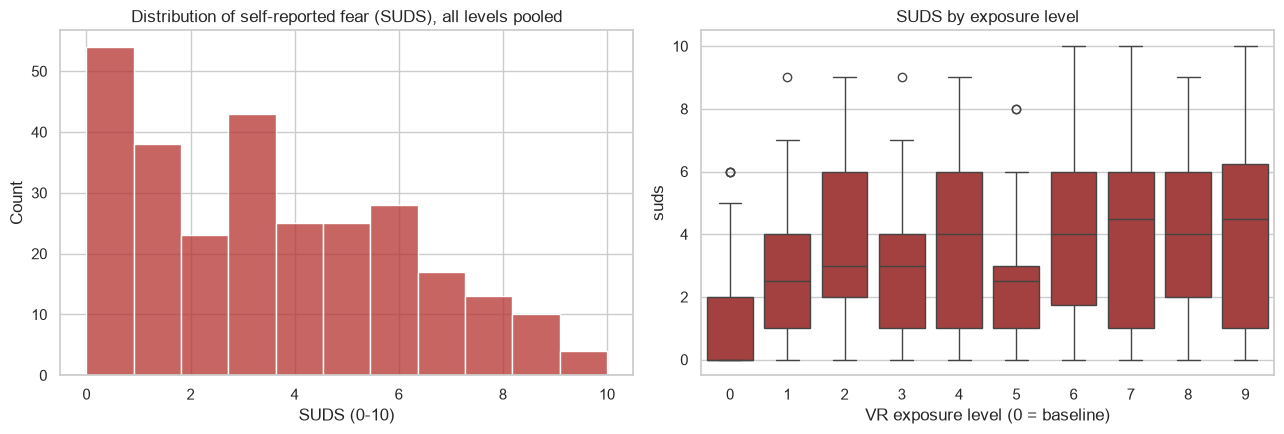

           mean       std  min  max
level                              
0      1.321429  2.055770    0    6
1      2.785714  2.315122    0    9
2      3.892857  2.629453    0    9
3      3.000000  2.464564    0    9
4      3.892857  2.935596    0    9
5      2.571429  2.150428    0    8
6      4.107143  2.858895    0   10
7      4.214286  2.935821    0   10
8      4.035714  2.821638    0    9
9      4.428571  3.120168    0   10


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(long_df["suds"], bins=11, ax=axes[0], color="#b3312e")
axes[0].set_title("Distribution of self-reported fear (SUDS), all levels pooled")
axes[0].set_xlabel("SUDS (0-10)")

sns.boxplot(data=long_df, x="level", y="suds", ax=axes[1], color="#b3312e")
axes[1].set_title("SUDS by exposure level")
axes[1].set_xlabel("VR exposure level (0 = baseline)")
plt.tight_layout()
plt.show()

print(long_df.groupby("level")["suds"].agg(["mean", "std", "min", "max"]))


A clear floor effect is visible at level 0 (baseline, pre-spider neutral VR): most
participants report 0 fear. Mean SUDS increases roughly monotonically with exposure level,
consistent with the exposure protocol working as intended (later levels bring the
participant closer to more/larger spiders).


## 3. Physiological measurements across exposure stages

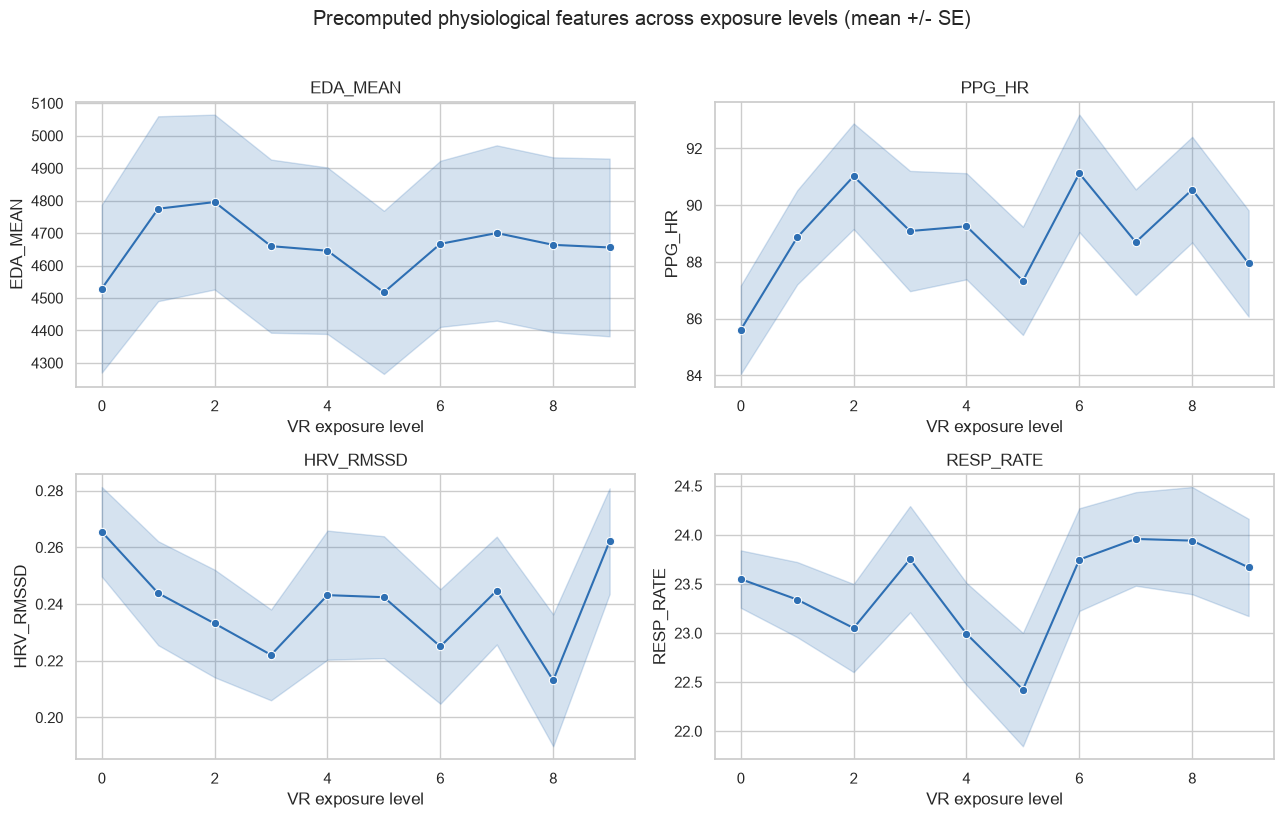

In [5]:
physio_cols_to_plot = ["EDA_MEAN", "PPG_HR", "HRV_RMSSD", "RESP_RATE"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, physio_cols_to_plot):
    sns.lineplot(data=long_df, x="level", y=col, errorbar="se", marker="o", ax=ax, color="#2e6fb3")
    ax.set_title(col)
    ax.set_xlabel("VR exposure level")
fig.suptitle("Precomputed physiological features across exposure levels (mean +/- SE)", y=1.02)
plt.tight_layout()
plt.show()


EDA and heart rate show a rise from baseline into the exposure levels, broadly tracking
the SUDS pattern above, but the physiological curves are visibly noisier and less
monotonic than the self-report curve -- an early hint at the subjective/physiological
dissociation the source paper investigates.


## 4. Within-participant vs. between-participant variation

In [6]:
icc_rows = []
for col in ["suds", "EDA_MEAN", "PPG_HR", "HRV_RMSSD"]:
    grand_mean = long_df[col].mean()
    between = long_df.groupby("participant_id")[col].mean()
    between_var = ((between - grand_mean) ** 2).mean()
    within_var = long_df.groupby("participant_id")[col].transform(lambda s: (s - s.mean()) ** 2).mean()
    icc_rows.append({
        "variable": col,
        "between_participant_variance": between_var,
        "within_participant_variance": within_var,
        "fraction_between": between_var / (between_var + within_var),
    })
pd.DataFrame(icc_rows)


,variable,between_participant_variance,within_participant_variance,fraction_between
0,suds,4.964732e+00,2.679643,0.649462
1,EDA_MEAN,1.867507e+06,46958.378721,0.975472
2,PPG_HR,7.448028e+01,22.635265,0.766924
3,HRV_RMSSD,6.207072e-03,0.004404,0.584955


A high `fraction_between` means a variable mostly separates *who* the participant is
(trait-like, stable baseline differences); a low value means it mostly varies *within* a
participant across exposure levels (state-like, reactive to the stimulus). This is why the
model comparison uses baseline-corrected (`_delta_baseline`) physiological features
alongside raw levels, and why cross-validation must be participant-grouped -- a
substantial share of the variance in every one of these variables is between-participant.


## 5. Subjective-physiological agreement and dissociation

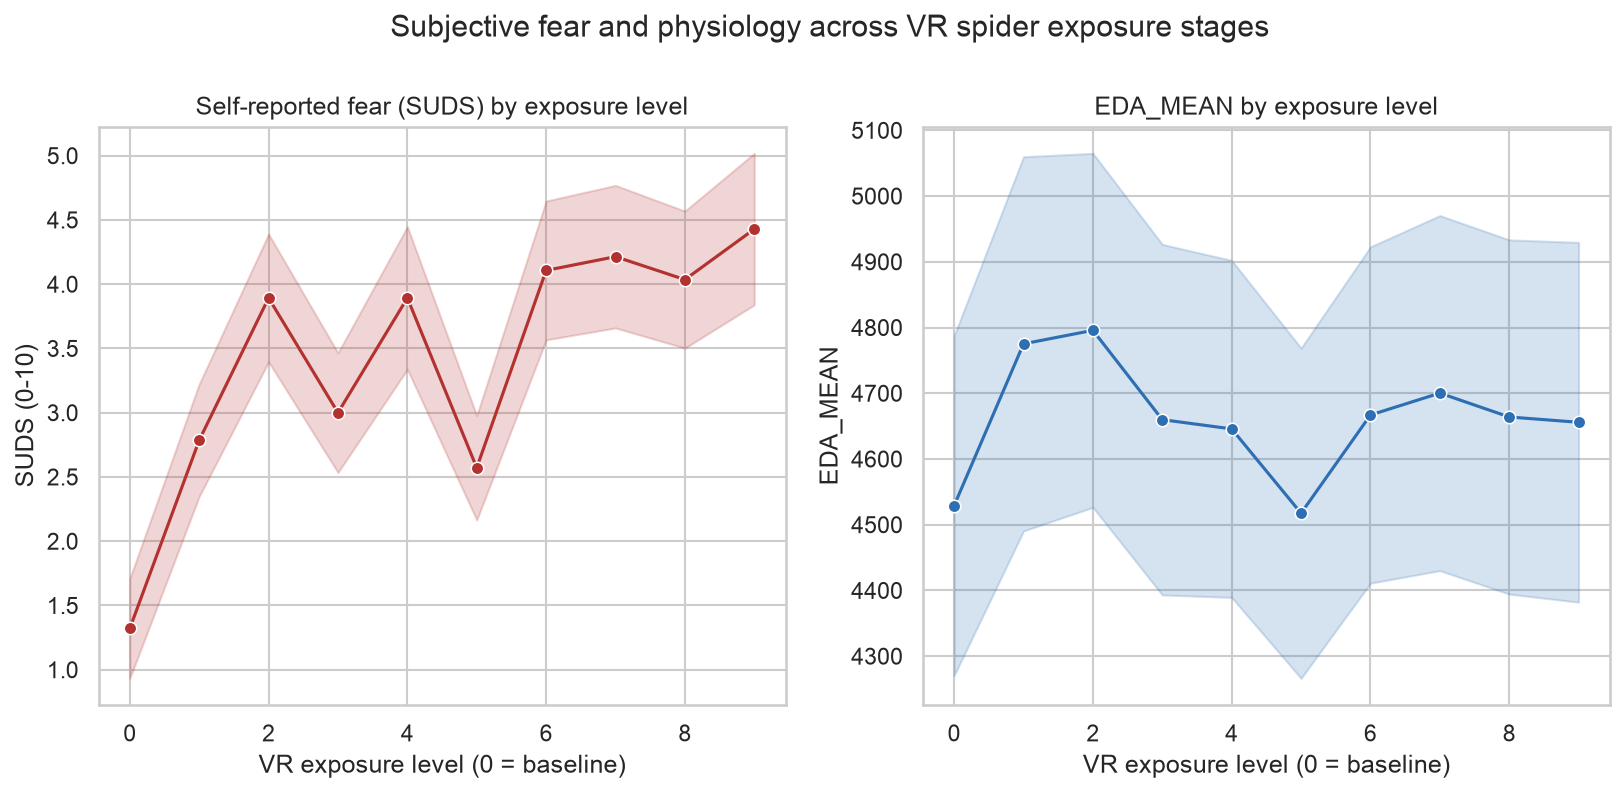

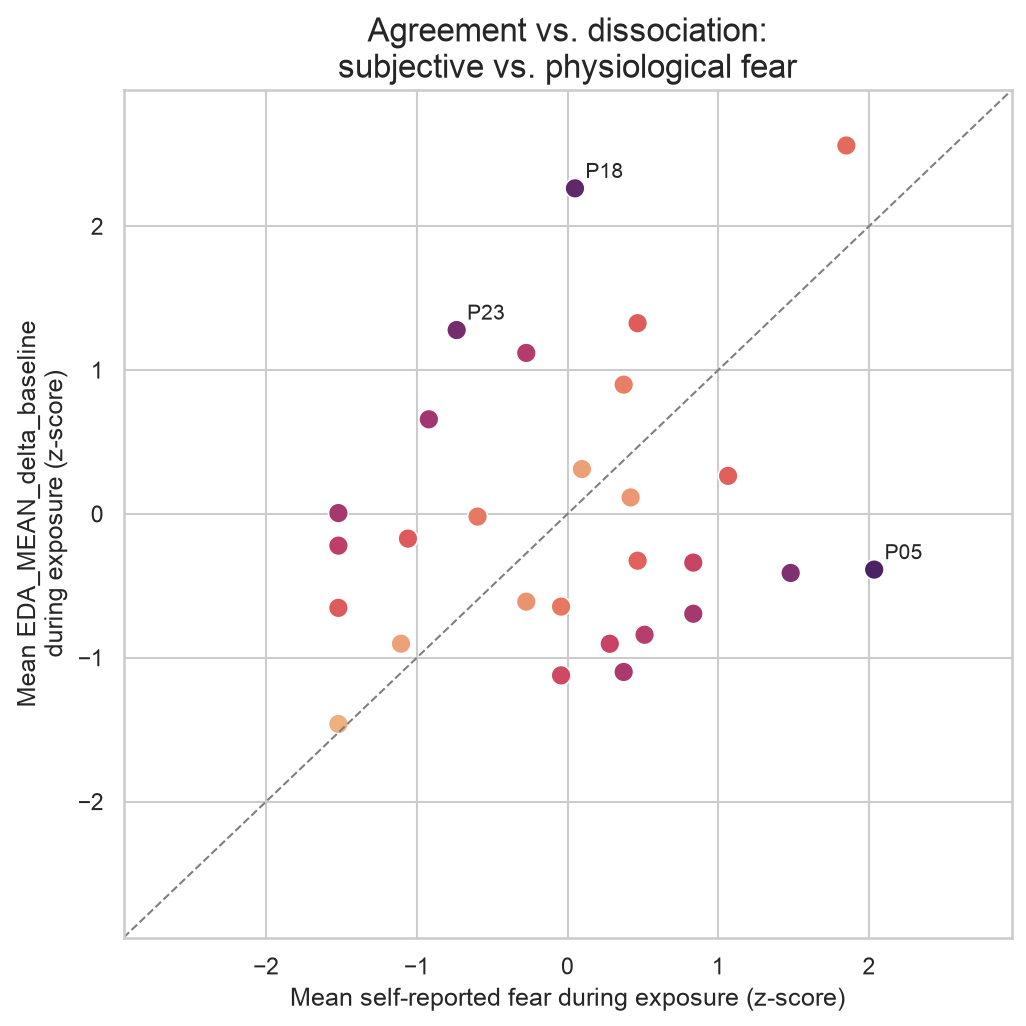

In [7]:
fig_path = visualization.plot_suds_and_physio_by_level(long_df)
fig_path2 = visualization.plot_dissociation(long_df)
from IPython.display import Image, display
display(Image(filename=str(fig_path)))
display(Image(filename=str(fig_path2)))


In [8]:
rm_corr = evaluation.repeated_measures_correlation(long_df, "participant_id", "EDA_MEAN_delta_baseline", "suds")
print("Within-participant (repeated-measures) correlation between EDA change from baseline and SUDS:")
print(rm_corr)

between_df = long_df.groupby("participant_id").agg(mean_suds=("suds", "mean"), mean_eda_delta=("EDA_MEAN_delta_baseline", "mean"))
from scipy.stats import pearsonr
r_between, p_between = pearsonr(between_df["mean_suds"], between_df["mean_eda_delta"])
print(f"\nBetween-participant correlation (mean SUDS vs mean EDA change): r={r_between:.2f}, p={p_between:.3f}")


Within-participant (repeated-measures) correlation between EDA change from baseline and SUDS:
{'r': 0.19364796381861168, 'p_value': 0.0011270114562450697, 'n_observations': 280}

Between-participant correlation (mean SUDS vs mean EDA change): r=0.20, p=0.307


Both the within-participant (repeated-measures) and between-participant correlations
between EDA and SUDS are positive but modest -- consistent with the source paper's title:
subjective and physiological fear are related, but far from interchangeable. Some
participants (see labeled outliers in the dissociation plot above) report high fear with
comparatively little physiological change, or vice versa. This is the central empirical
motivation for treating SUDS and physiology as two distinct signals rather than proxies
for one another, and for never treating physiological arousal as proof of fear.


## 6. Raw-signal processing demo (NeuroKit2) with a sanity check

The main modeling pipeline (Section 7 below, and `src/vr_fear_prediction/modeling.py`)
uses the dataset authors' precomputed per-level physiological features from
`summary.csv`. That is the honest choice given that the raw per-participant recordings are
~9 GB in total (150 MB-1.2 GB per participant) and cannot reasonably be processed in full
for a small student project or in CI.

This section instead demonstrates the from-scratch feature-extraction pipeline in
`vr_fear_prediction.signal_processing` (tested in `tests/test_signal_processing.py` with
small synthetic fixtures) on one real participant's raw recording, and compares it against
that participant's precomputed features as an independent sanity check.

Run `python -m vr_fear_prediction.download_data --with-raw-signals p31` first to fetch this
one raw file (~150 MB) if it is not already present.


In [9]:
raw_signal_path = PROJECT_ROOT / "data" / "raw" / "signals" / "p31.csv"

if raw_signal_path.exists():
    from vr_fear_prediction.signal_processing import (
        load_raw_participant_signal, extract_level_window, extract_all_features,
    )

    raw_signal_df = load_raw_participant_signal(raw_signal_path)
    print("Raw recording shape:", raw_signal_df.shape)

    demo_rows = []
    for level in range(10):
        window = extract_level_window(raw_signal_df, level)
        feats = extract_all_features(window)
        feats["level"] = level
        feats["duration_s"] = window.duration_seconds
        feats["sampling_rate_hz"] = window.sampling_rate_hz
        demo_rows.append(feats)
    demo_df = pd.DataFrame(demo_rows).set_index("level")
    display(demo_df[["duration_s", "sampling_rate_hz", "cardiac_n_beats", "cardiac_hr_mean", "cardiac_rmssd", "eda_tonic_mean", "eda_scr_count", "resp_rate_bpm"]])
else:
    print(f"{raw_signal_path} not found -- skipping raw-signal demo. "
          "Run `python -m vr_fear_prediction.download_data --with-raw-signals p31` to fetch it.")


/Users/sivanjaeger/Desktop/Projects/vr-fear-response-prediction/src/vr_fear_prediction/signal_processing.py:67: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path, sep=";", encoding="utf-8-sig")


Raw recording shape: (753995, 14)


,duration_s,sampling_rate_hz,cardiac_n_beats,cardiac_hr_mean,cardiac_rmssd,eda_tonic_mean,eda_scr_count,resp_rate_bpm
level,,,,,,,,
0,125.187246,2070.393375,103.0,62.633265,757.045808,4547.642994,20.0,16.774872
1,23.708483,2074.688797,19.0,57.957763,NaN,4780.556516,5.0,17.715178
2,15.938525,2070.393375,19.0,84.043356,NaN,4878.092520,3.0,18.822319
3,17.015625,2070.393375,17.0,69.156686,NaN,4962.069365,2.0,14.104683
4,15.673628,2053.388090,19.0,82.653415,NaN,4798.336473,3.0,15.312345
5,14.683394,2016.129032,17.0,79.497549,NaN,4688.802388,5.0,16.344995
6,19.987572,2032.520325,25.0,90.984072,NaN,4770.441925,5.0,18.011192
7,17.786486,2074.688797,21.0,85.409763,NaN,4793.882773,4.0,13.493390
8,20.191509,2074.688797,24.0,85.354671,NaN,4693.225723,3.0,17.829277


,level,official_PPG_HR,from_scratch_cardiac_hr_mean,official_EDA_MEAN,from_scratch_eda_tonic_mean
0,0,74.7678,62.633265,4551.6040,4547.642994
1,1,80.9819,57.957763,4771.9198,4780.556516
2,2,90.3444,84.043356,4868.6439,4878.092520
3,3,70.5219,69.156686,4941.3492,4962.069365
4,4,88.0439,82.653415,4794.0359,4798.336473
5,5,69.4634,79.497549,4683.6664,4688.802388
6,6,87.0522,90.984072,4763.6148,4770.441925
7,7,84.3313,85.409763,4793.1092,4793.882773
8,8,86.1727,85.354671,4696.1370,4693.225723
9,9,78.1387,71.901068,4688.8579,4691.844354


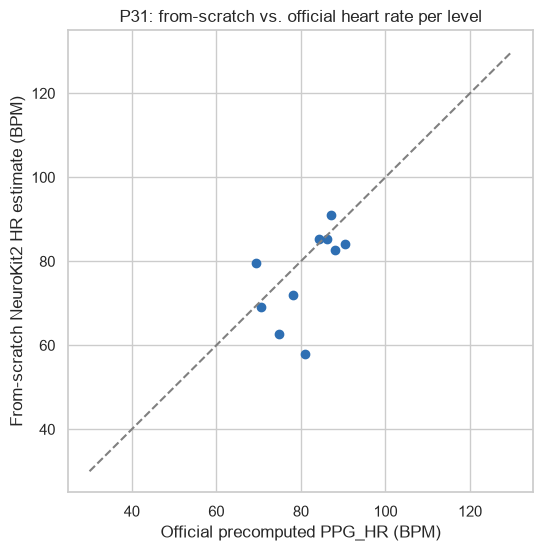

In [10]:
if raw_signal_path.exists():
    p31_official = raw_df[raw_df["participant"] == "P31"].iloc[0]
    compare_rows = []
    for level in range(10):
        compare_rows.append({
            "level": level,
            "official_PPG_HR": p31_official[f"PPG_HR_level{level}"],
            "from_scratch_cardiac_hr_mean": demo_df.loc[level, "cardiac_hr_mean"],
            "official_EDA_MEAN": p31_official[f"EDA_MEAN_level{level}"],
            "from_scratch_eda_tonic_mean": demo_df.loc[level, "eda_tonic_mean"],
        })
    compare_df = pd.DataFrame(compare_rows)
    display(compare_df)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(compare_df["official_PPG_HR"], compare_df["from_scratch_cardiac_hr_mean"], color="#2e6fb3")
    lims = [30, 130]
    ax.plot(lims, lims, linestyle="--", color="gray")
    ax.set_xlabel("Official precomputed PPG_HR (BPM)")
    ax.set_ylabel("From-scratch NeuroKit2 HR estimate (BPM)")
    ax.set_title("P31: from-scratch vs. official heart rate per level")
    plt.show()


**Honest caveat.** The from-scratch heart-rate estimates broadly track the official
precomputed values in direction, but do not match them closely in absolute terms, and the
short-window RMSSD estimates in particular are implausible (far outside physiologically
plausible ranges) even on windows that pass the `MIN_WINDOW_SECONDS_FOR_HRV` gate. This is
most likely because a defensible PPG pipeline needs participant- and device-specific
filtering/artifact-rejection tuning that the dataset authors' pipeline includes and this
minimal demo does not attempt to reproduce. This discrepancy is itself a useful, honest
finding: it is exactly why the main modeling pipeline uses the dataset authors' precomputed
features rather than a quickly-built from-scratch pipeline, and why any raw-signal
processing claims in this project are scoped to "demonstration", not "production feature
extraction".


## 7. Model comparison: context-only vs. physiology-only vs. combined

In [11]:
metrics_path = PROJECT_ROOT / "reports" / "metrics.json"
metrics = json.loads(metrics_path.read_text())

rows = []
for feature_set, models in metrics["feature_sets"].items():
    for model_name, result in models.items():
        if model_name == "best_model":
            continue
        rows.append({
            "feature_set": feature_set,
            "model": model_name,
            "cv_MAE_mean": result["cv"]["MAE_mean"],
            "cv_MAE_std": result["cv"]["MAE_std"],
            "test_MAE": result["held_out_test"]["MAE"],
            "test_RMSE": result["held_out_test"]["RMSE"],
            "test_R2": result["held_out_test"]["R2"],
        })
results_df = pd.DataFrame(rows).sort_values(["feature_set", "cv_MAE_mean"])
results_df


,feature_set,model,cv_MAE_mean,cv_MAE_std,test_MAE,test_RMSE,test_R2
7,combined,ridge,2.090789,0.204580,0.893836,1.360349,0.567264
8,combined,random_forest,2.185147,0.341260,1.447111,1.868965,0.183183
6,combined,dummy_mean,2.373960,0.505957,2.557273,2.821635,-0.861764
1,context_only,ridge,1.821191,0.115909,1.307449,1.863439,0.188005
2,context_only,random_forest,1.942737,0.308919,1.571889,1.939831,0.120065
0,context_only,dummy_mean,2.373960,0.505957,2.557273,2.821635,-0.861764
3,physiology_only,dummy_mean,2.373960,0.505957,2.557273,2.821635,-0.861764
5,physiology_only,random_forest,2.472563,0.255164,1.731000,2.128242,-0.059168
4,physiology_only,ridge,2.636916,0.580529,1.889753,2.191752,-0.123326


In [12]:
pv = metrics["physiology_value_assessment"]
print("Original held-out split:", pv["original_held_out_split"])
print("Participant-aware CV:   ", pv["participant_aware_cv"])
print()
print("Overall conclusion:", pv["overall_conclusion"])
print(pv["summary"])
print()
print("Overall best (by participant-aware CV MAE):", metrics["overall_best"])


Original held-out split: {'context_only_best_test_MAE': 1.3074485837209089, 'combined_best_test_MAE': 0.8938359822378206, 'combined_improves_on_context_original_split': True}
Participant-aware CV:    {'context_only_best_cv_MAE_mean': 1.8211912435091377, 'combined_best_cv_MAE_mean': 2.090789193412023, 'combined_improves_on_context_cv': False}

Overall conclusion: inconclusive
Evidence that physiology adds predictive value beyond context is inconclusive. The combined model performs better on one held-out participant split, but worse under participant-aware cross-validation. With only 28 participants, this difference is unstable and may depend strongly on which participants are held out.

Overall best (by participant-aware CV MAE): {'feature_set': 'context_only', 'model': 'ridge'}


## 8. Robustness: is that result stable?

The original held-out split and participant-aware CV disagree above (combined wins the
split, context-only wins CV). With only 28 participants, a single six-participant test
set is not automatically more informative than a five-fold CV estimate, so before drawing
any conclusion we check how stable the comparison actually is: does combined keep winning
if we hold out a *different* set of participants?


In [13]:
repeated_path = PROJECT_ROOT / "reports" / "repeated_holdout_results.csv"
repeated_df = pd.read_csv(repeated_path)
print(f"{len(repeated_df)} repeated participant-level holdout splits")
repeated_df.head()


50 repeated participant-level holdout splits


,split_id,seed,n_train_participants,n_test_participants,context_only_MAE,combined_MAE,diff_context_minus_combined,context_only_best_alpha,combined_best_alpha
0,0,1000,22,6,3.135581,1.730497,1.405084,0.1,50.0
1,1,1001,22,6,1.669110,1.912596,-0.243486,50.0,50.0
2,2,1002,22,6,1.328390,1.647117,-0.318727,50.0,50.0
3,3,1003,22,6,1.423081,1.504144,-0.081064,50.0,50.0
4,4,1004,22,6,2.063524,1.588597,0.474927,10.0,50.0


combined better in 54% of 50 splits
paired difference (context - combined): mean=0.081, median=0.023, 95% interval=[-0.317, 1.221]


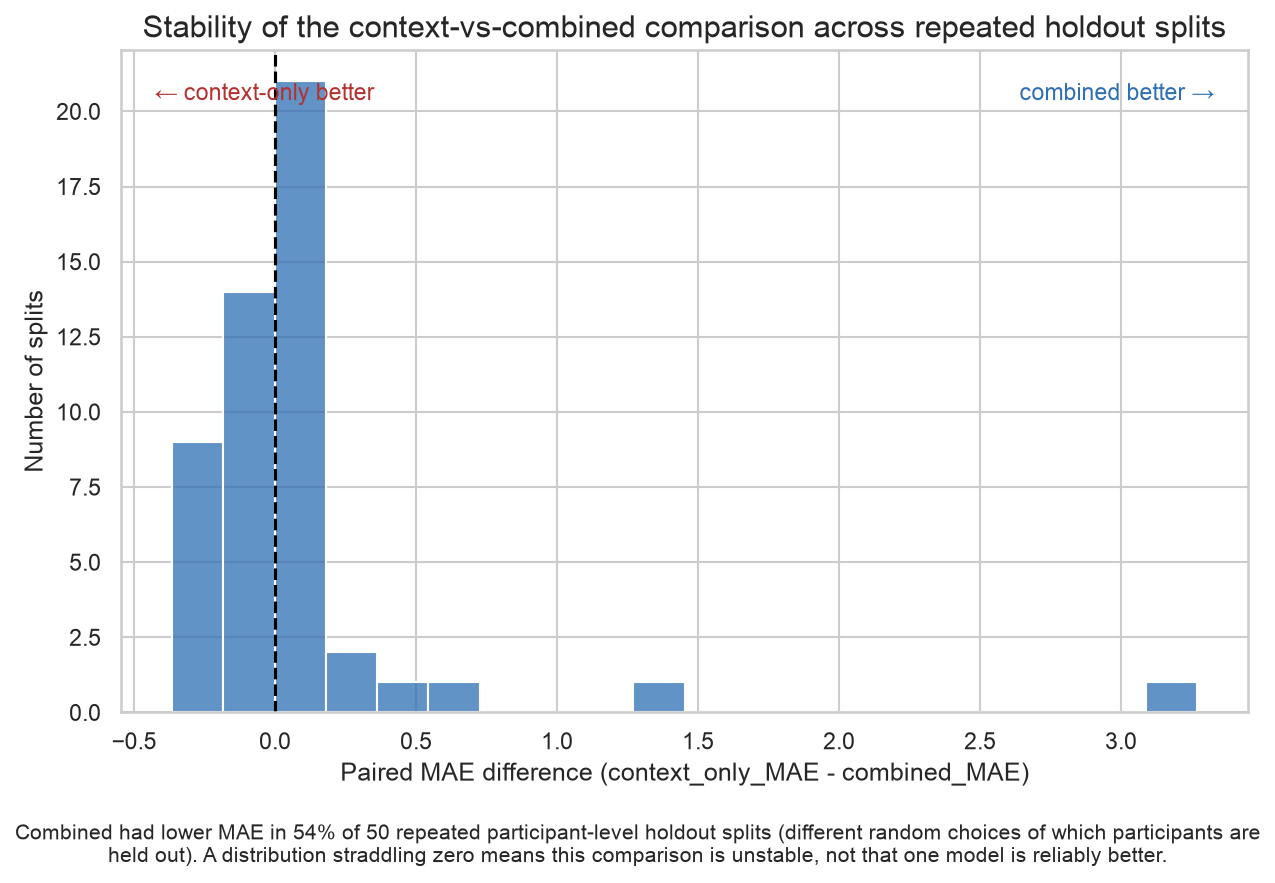

In [14]:
summary = pv["repeated_participant_holdout"]
diff_summary = summary["paired_difference_context_minus_combined"]
print(f"combined better in {diff_summary['fraction_splits_combined_better']:.0%} of {summary['n_splits']} splits")
print(f"paired difference (context - combined): mean={diff_summary['mean']:.3f}, "
      f"median={diff_summary['median']:.3f}, "
      f"95% interval=[{diff_summary['ci_2.5pct']:.3f}, {diff_summary['ci_97.5pct']:.3f}]")

fig_path = visualization.plot_paired_mae_difference(
    repeated_df, "Stability of the context-vs-combined comparison across repeated holdout splits", "paired_mae_difference_repeated_holdout.png"
)
display(Image(filename=str(fig_path)))


A distribution of the paired MAE difference centered close to zero, with roughly half
the splits favoring each side, is the signature of an unstable comparison rather than a
reliable winner. That is what we see here -- which is why this project reports the
conclusion as **inconclusive** rather than picking whichever single number looked best.


### Sensitivity check: does the baseline (floor-effect) level drive this?

Level 0 has near-zero SUDS for most participants and every baseline-corrected
physiological delta is trivially 0 there, which could make prediction artificially easy.
As a secondary check (not a replacement for the primary analysis above), we repeat the
comparison using only exposure levels 1-9.


Sensitivity analysis: 252 observations, levels [1, 2, 3, 4, 5, 6, 7, 8, 9]
Sensitivity overall conclusion: inconclusive
Conclusion materially changed vs. primary: False
Fraction-combined-better delta vs. primary: -0.12


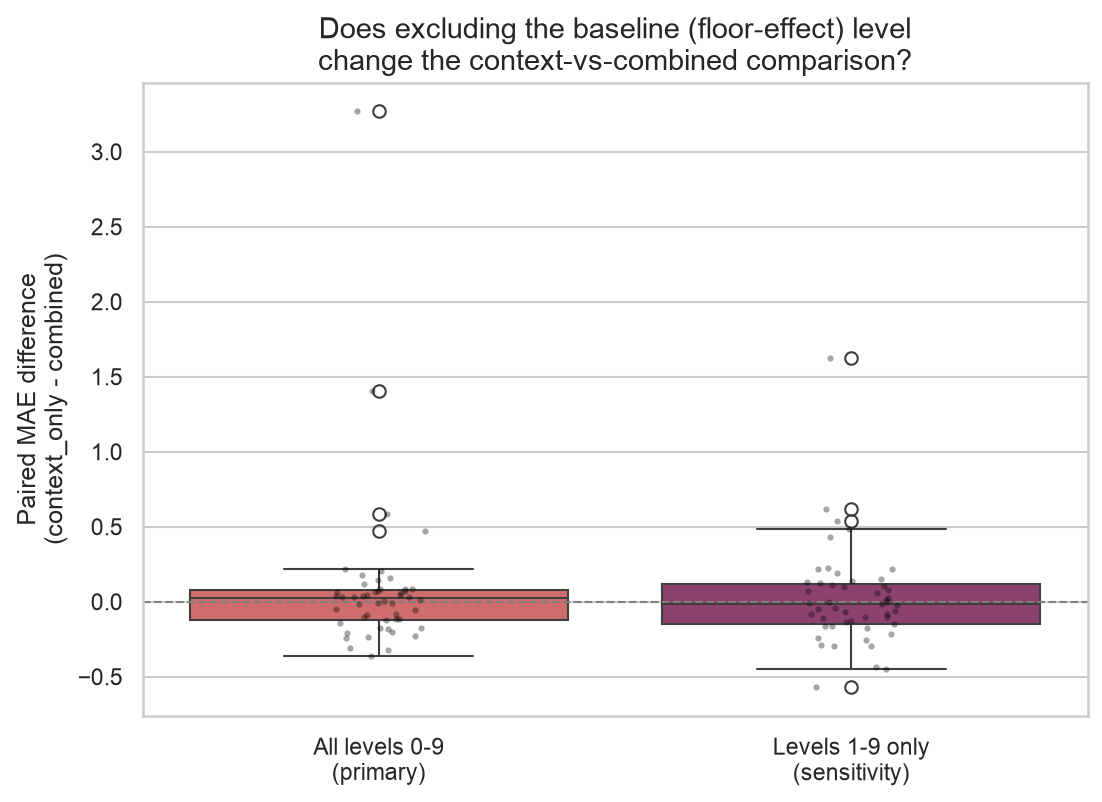

In [15]:
sensitivity = metrics["sensitivity_excluding_baseline"]
sens_pv = sensitivity["physiology_value_assessment"]
print(f"Sensitivity analysis: {sensitivity['n_observations']} observations, levels {sensitivity['levels_included']}")
print("Sensitivity overall conclusion:", sens_pv["overall_conclusion"])
print(f"Conclusion materially changed vs. primary: {sensitivity['conclusion_materially_changed_vs_primary']}")
print(f"Fraction-combined-better delta vs. primary: {sensitivity['fraction_combined_better_delta_vs_primary']:+.2f}")

sensitivity_repeated_df = pd.read_csv(PROJECT_ROOT / "reports" / "repeated_holdout_results_excluding_baseline.csv")
fig_path = visualization.plot_baseline_sensitivity_comparison(repeated_df, sensitivity_repeated_df, "baseline_sensitivity_comparison.png")
display(Image(filename=str(fig_path)))


See `reports/metrics.json`, `reports/model_card.md`, and the main `README.md` for the
full results table, figures, and interpretation. The short version: on this dataset,
whether physiology adds predictive value beyond context is **inconclusive** -- the
original held-out split and participant-aware CV disagree, a 50-split repeated holdout
evaluation shows the comparison is close to a coin flip, and excluding the baseline
floor-effect level does not change that picture (see README.md "Results").
